# 04 - Re-ranking y evaluación

En el cuaderno 03 el asistente básico acertó casi todo, pero en la pregunta de Valladolid se dejó una estación: el trozo que la contenía no estaba entre los 4 recuperados. El problema no era el LLM, sino la búsqueda.

En este cuaderno probamos una mejora en la fase de recuperación, el **re-ranking**, y medimos con un conjunto de preguntas si de verdad mejora frente a la versión básica.

# Qué es el re-ranking

## Bi-encoder (lo que usamos hasta ahora)

El modelo e5 es un **bi-encoder**: convierte la pregunta en un vector y cada trozo en otro vector, **por separado**, y luego compara los vectores. Como los vectores de los trozos se calculan una sola vez y se guardan en Chroma, buscar entre 850 trozos es casi instantáneo. El inconveniente es que la pregunta y el trozo nunca se leen juntos, así que se pierden matices (por ejemplo, que la pregunta pide justo la provincia de Valladolid y no cualquier estación de Castilla y León).

## Cross-encoder (la mejora)

Un **cross-encoder** recibe la pregunta y el trozo **juntos**, como un único texto, y devuelve una puntuación de lo bien que ese trozo responde a esa pregunta. Al leerlos a la vez es más preciso, pero mucho más lento: hay que pasar el modelo una vez por cada pareja pregunta-trozo, y no se puede calcular nada por adelantado.

## Por qué recuperar 20 y quedarnos con 4

Pasar el cross-encoder por los 850 trozos en cada pregunta sería demasiado lento. Por eso combinamos los dos:

1. El bi-encoder (rápido) trae de Chroma los 20 trozos más parecidos: una lista amplia de candidatos donde es probable que esté el bueno, aunque no salga entre los 4 primeros.
2. El cross-encoder (preciso) puntúa solo esos 20 y los reordena.
3. Nos quedamos con los 4 mejores según el cross-encoder y se los damos al LLM, igual que en el cuaderno 03.

Así el LLM recibe el mismo número de trozos, pero mejor elegidos.

# Importaciones

Las mismas del cuaderno 03 y, además:

- **CrossEncoder** (de sentence_transformers): carga el modelo de re-ranking.
- **pandas**: para la tabla de resultados.
- **numpy**: para ordenar las puntuaciones del cross-encoder.
- **matplotlib**: para el gráfico comparativo.

In [1]:
import os
import time
from dotenv import load_dotenv
import chromadb
from sentence_transformers import SentenceTransformer, CrossEncoder
from groq import Groq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

W1025 11:51:36.219000 33443 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


# Carga de la clave, Chroma, embeddings y Groq

Lo mismo que en el cuaderno 03: la clave desde .env (sin mostrarla), la colección taller de Chroma, el modelo de embeddings e5 y el cliente de Groq.

In [2]:
load_dotenv('../.env')
print('Clave cargada:', os.getenv('GROQ_API_KEY') is not None)

Clave cargada: True


In [3]:
client = chromadb.PersistentClient(path='../chroma_db')
collection = client.get_collection('taller')
collection.count()

850

In [4]:
model = SentenceTransformer('intfloat/multilingual-e5-small')
cliente = Groq(api_key=os.getenv('GROQ_API_KEY'))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

# Modelo de re-ranking

Usamos **cross-encoder/mmarco-mMiniLMv2-L12-H384-v1**: es un cross-encoder multilingüe (incluye español) entrenado con mMARCO, una colección de preguntas y pasajes de búsqueda traducida a muchos idiomas, justo nuestra tarea. Lo elegimos frente a BAAI/bge-reranker-v2-m3 porque es mucho más ligero (unos 470 MB frente a más de 2 GB) y va con soltura en un portátil, mientras que el bge sería más lento para una mejora pequeña en un proyecto de este tamaño.

In [5]:
reranker = CrossEncoder('cross-encoder/mmarco-mMiniLMv2-L12-H384-v1')

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

# Funciones de búsqueda

## Búsqueda básica

Es la función buscar del cuaderno 03: devuelve los 4 trozos más parecidos según e5 y sus fuentes.

In [6]:
def buscar_basico(pregunta, k=4):
    vector = model.encode('query: ' + pregunta, normalize_embeddings=True).tolist()
    resultados = collection.query(query_embeddings=[vector], n_results=k)
    trozos = resultados['documents'][0]
    fuentes = []
    for metadato in resultados['metadatas'][0]:
        fuentes.append(metadato['fuente'])
    return trozos, fuentes

## Búsqueda con re-ranking

1. Pedimos 20 candidatos con la búsqueda básica.
2. Formamos parejas [pregunta, trozo] y el cross-encoder da una puntuación a cada una con predict (cuanto más alta, más relevante).
3. np.argsort ordena las posiciones de menor a mayor puntuación; con [::-1] le damos la vuelta para tener primero las mejores.
4. Nos quedamos con los 4 primeros.

In [7]:
def buscar_reranking(pregunta, candidatos=20, k=4):
    trozos, fuentes = buscar_basico(pregunta, k=candidatos)
    parejas = []
    for trozo in trozos:
        parejas.append([pregunta, trozo])
    puntuaciones = reranker.predict(parejas, show_progress_bar=False)
    orden = np.argsort(puntuaciones)[::-1]
    mejores_trozos = []
    mejores_fuentes = []
    for i in orden[:k]:
        mejores_trozos.append(trozos[i])
        mejores_fuentes.append(fuentes[i])
    return mejores_trozos, mejores_fuentes

# Prompt y generación

Repetimos construir_prompt y el prompt de sistema del cuaderno 03. La función generar recibe la pregunta y los trozos ya elegidos (por cualquiera de las dos búsquedas) y devuelve la respuesta del LLM. Así las dos versiones solo se diferencian en la búsqueda, y la comparación es justa.

El plan gratuito de Groq permite unos 8.000 tokens por minuto con este modelo, y cada llamada gasta entre 1.500 y 2.000 (contexto, pregunta y respuesta). Por eso, después de cada llamada hacemos una pausa de 15 segundos con time.sleep: así no pasamos de unas 4 llamadas por minuto y no salta el error 429 de límite superado.

In [8]:
def construir_prompt(pregunta, trozos, fuentes):
    contexto = ''
    for i in range(len(trozos)):
        contexto = contexto + '[' + str(i + 1) + '] Fuente: ' + fuentes[i] + '\n' + trozos[i] + '\n\n'
    prompt = 'Contexto:\n' + contexto + 'Pregunta: ' + pregunta
    return prompt

In [9]:
prompt_sistema = '''Eres el asistente de un taller de vehículos en España.
Responde en español, de forma breve y clara, usando SOLO la información del contexto.
Indica al final la fuente o fuentes que has usado (el nombre del archivo).
Si el contexto no contiene la respuesta, di exactamente: No lo sé con la información disponible.'''

In [10]:
def generar(pregunta, trozos, fuentes):
    prompt = construir_prompt(pregunta, trozos, fuentes)
    respuesta = cliente.chat.completions.create(
        model='openai/gpt-oss-120b',
        temperature=0.1,
        messages=[{'role': 'system', 'content': prompt_sistema},
                  {'role': 'user', 'content': prompt}])
    time.sleep(15)
    return respuesta.choices[0].message.content

# Ejemplo lado a lado

Antes de evaluar, vemos la diferencia con la pregunta que falló en el cuaderno 03.

In [11]:
pregunta = '¿Qué estaciones ITV hay en la provincia de Valladolid?'

trozos_b, fuentes_b = buscar_basico(pregunta)
trozos_r, fuentes_r = buscar_reranking(pregunta)

print('BÁSICO - fuentes:', fuentes_b)
print(generar(pregunta, trozos_b, fuentes_b))
print()
print('=' * 60)
print()
print('RE-RANKING - fuentes:', fuentes_r)
print(generar(pregunta, trozos_r, fuentes_r))

BÁSICO - fuentes: ['registro_estaciones_itv_2026.csv', 'registro_estaciones_itv_2026.csv', 'registro_estaciones_itv_2026.csv', 'registro_estaciones_itv_2026.csv']
En la provincia de Valladolid hay las siguientes estaciones ITV:

- ITV 4701 (Grupo Itevelesa, S.L.) – P.I. Argales, C/. Vázquez de Menchaca, 2, Valladolid.  
- ITV 4702 (Itevecasa) – P.I. de la Vega, Parc. 4, Tordesillas (Valladolid).  
- ITV 4703 (Grupo Itevelesa, S.L.) – P.I. San Cristóbal, C/. Acero, Parc. 16, Valladolid.  
- ITV 4704 (Grupo Itevelesa, S.L.) – Polígono Industrial “Ctra. Villalpando II”, Parcelas 58‑59, Medina Riociego (Valladolid).  
- ITV 47A2 (Itevecasa) – Unidad Móvil Agrícola y Ciclomotores, Tordesillas (Valladolid).  
- ITV 47A3 (Grupo Itevelesa, S.L.) – Unidad Móvil Agrícola y Ciclomotores, Valladolid (Valladolid).

**Fuentes:** [1], [2] (registro_estaciones_itv_2026.csv).


RE-RANKING - fuentes: ['registro_estaciones_itv_2026.csv', 'registro_estaciones_itv_2026.csv', 'registro_estaciones_itv_2026.c

# Conjunto de evaluación

Para comparar las dos versiones con algo más que una impresión, preparamos 10 preguntas variadas, cada una con:

- **fuente**: el archivo o archivos donde está la respuesta.
- **dato**: un fragmento de texto que tiene que aparecer en un trozo recuperado para que contenga la respuesta.
- **referencia**: la respuesta correcta, comprobada a mano contra los documentos.

Cubren la FAQ del taller, el Real Decreto de talleres, el Real Decreto de ITV, la página de la DGT, el CSV de estaciones (dos provincias) y una pregunta fuera de tema, cuya respuesta correcta es que no lo sabe.

In [12]:
preguntas = [
    {'pregunta': '¿Abre el taller los sábados?',
     'fuente': ['faq_taller.md'], 'dato': '9:00 a 13:00',
     'referencia': 'Sí, los sábados de 9:00 a 13:00, solo para entregas y recogidas.'},
    {'pregunta': '¿Cuándo es gratis el coche de sustitución?',
     'fuente': ['faq_taller.md'], 'dato': '300',
     'referencia': 'Es gratuito en reparaciones de más de 300 €; en el resto cuesta 20 € al día.'},
    {'pregunta': '¿Cuánto dura la garantía de una reparación en un taller?',
     'fuente': ['rd_1457_1986_talleres_reparacion.pdf', 'faq_taller.md'], 'dato': '2.000',
     'referencia': 'Tres meses o 2.000 kilómetros (en vehículos industriales, quince días o 2.000 kilómetros).'},
    {'pregunta': '¿Dónde tiene que poner un taller la placa-distintivo?',
     'fuente': ['rd_1457_1986_talleres_reparacion.pdf'], 'dato': 'fachada',
     'referencia': 'En la fachada del edificio, en un lugar fácilmente visible.'},
    {'pregunta': '¿En qué plazo hay que reparar los defectos leves detectados en la ITV?',
     'fuente': ['rd_920_2017_inspeccion_tecnica_vehiculos.html', 'rd_920_2017_inspeccion_tecnica_vehiculos.xml'], 'dato': 'dos meses',
     'referencia': 'En un plazo máximo de dos meses, sin necesidad de nueva inspección.'},
    {'pregunta': '¿Qué resultado tiene la ITV si se detecta un defecto muy grave?',
     'fuente': ['rd_920_2017_inspeccion_tecnica_vehiculos.html', 'rd_920_2017_inspeccion_tecnica_vehiculos.xml'], 'dato': 'negativo',
     'referencia': 'El resultado de la inspección es negativo.'},
    {'pregunta': '¿Cómo puedo consultar si mi coche tiene una llamada a revisión pendiente?',
     'fuente': ['dgt_llamadas_a_revision.html'], 'dato': 'Cl@ve',
     'referencia': 'En el servicio de la DGT, identificándose con certificado o credenciales Cl@ve.'},
    {'pregunta': '¿Qué estaciones ITV hay en la provincia de Valladolid?',
     'fuente': ['registro_estaciones_itv_2026.csv'], 'dato': '(Valladolid,',
     'referencia': 'Valladolid (4701 y 4703), Tordesillas (4702), Medina de Rioseco (4704), Peñafiel (4705) y las unidades móviles 47A2 y 47A3.'},
    {'pregunta': '¿Hay alguna estación ITV en Utrera?',
     'fuente': ['registro_estaciones_itv_2026.csv'], 'dato': 'UTRERA',
     'referencia': 'Sí, la estación 4131, en Utrera (Sevilla).'},
    {'pregunta': '¿Quién ganó el Mundial de fútbol de 2010?',
     'fuente': [], 'dato': '',
     'referencia': 'No lo sé con la información disponible.'}
]
len(preguntas)

10

# Métricas

## 1. Acierto de recuperación

Para cada pregunta miramos si **alguno de los 4 trozos** recuperados viene de la fuente esperada **y** contiene el dato. Vale 1 si es así y 0 si no. La media es el porcentaje de preguntas en las que la búsqueda le ha dado al LLM la información necesaria. Mide solo la búsqueda, que es lo que cambia el re-ranking.

La pregunta fuera de tema no tiene fuente, así que no cuenta en esta métrica.

In [13]:
def acierto_recuperacion(trozos, fuentes, fuente_esperada, dato):
    for i in range(len(trozos)):
        if fuentes[i] in fuente_esperada and dato.lower() in trozos[i].lower():
            return 1
    return 0

## 2. Respuesta correcta (LLM como juez)

Comparar a mano 20 respuestas cada vez que cambiamos algo es lento, así que usamos el propio LLM como juez, con un criterio claro y cerrado: la respuesta es CORRECTO si contiene la información esencial de la referencia y no la contradice; si le falta un dato clave, lo contradice o dice que no lo sabe cuando sí había respuesta, es INCORRECTO. Le pedimos que conteste solo con una de esas dos palabras.

Es una medida aproximada: un juez automático puede equivocarse, por eso al final revisamos las respuestas a mano y lo comentamos en las conclusiones.

Limitamos la respuesta del juez con max_tokens=300: solo tiene que decir una palabra, y así gasta menos tokens del límite por minuto.

In [14]:
prompt_juez = '''Eres un evaluador. Compara la RESPUESTA con la REFERENCIA.
Responde CORRECTO si la respuesta contiene la información esencial de la referencia y no la contradice.
Responde INCORRECTO si le falta un dato clave, lo contradice, o dice que no lo sabe cuando la referencia sí da una respuesta.
Contesta solo con una palabra: CORRECTO o INCORRECTO.'''

def juzgar(pregunta, respuesta, referencia):
    mensaje = 'PREGUNTA: ' + pregunta + '\nREFERENCIA: ' + referencia + '\nRESPUESTA: ' + respuesta
    salida = cliente.chat.completions.create(
        model='openai/gpt-oss-120b',
        temperature=0,
        max_tokens=300,
        messages=[{'role': 'system', 'content': prompt_juez},
                  {'role': 'user', 'content': mensaje}])
    time.sleep(15)
    texto = salida.choices[0].message.content.upper()
    if 'INCORRECTO' in texto:
        return 0
    return 1

# Evaluación

Recorremos las 10 preguntas. Para cada una, con las dos búsquedas: recuperamos los trozos, calculamos el acierto de recuperación, generamos la respuesta y el juez la califica. Guardamos todo en una lista y la pasamos a una tabla.

Por las pausas, esta celda tarda unos 10 minutos (40 llamadas a Groq).

In [15]:
filas = []
for p in preguntas:
    trozos_b, fuentes_b = buscar_basico(p['pregunta'])
    trozos_r, fuentes_r = buscar_reranking(p['pregunta'])
    respuesta_b = generar(p['pregunta'], trozos_b, fuentes_b)
    respuesta_r = generar(p['pregunta'], trozos_r, fuentes_r)
    fila = {'pregunta': p['pregunta']}
    if len(p['fuente']) > 0:
        fila['recup_basico'] = acierto_recuperacion(trozos_b, fuentes_b, p['fuente'], p['dato'])
        fila['recup_reranking'] = acierto_recuperacion(trozos_r, fuentes_r, p['fuente'], p['dato'])
    else:
        fila['recup_basico'] = np.nan
        fila['recup_reranking'] = np.nan
    fila['resp_basico'] = juzgar(p['pregunta'], respuesta_b, p['referencia'])
    fila['resp_reranking'] = juzgar(p['pregunta'], respuesta_r, p['referencia'])
    fila['texto_basico'] = respuesta_b
    fila['texto_reranking'] = respuesta_r
    filas.append(fila)

resultados = pd.DataFrame(filas)
resultados[['pregunta', 'recup_basico', 'recup_reranking', 'resp_basico', 'resp_reranking']]

,pregunta,recup_basico,recup_reranking,resp_basico,resp_reranking
0,¿Abre el taller los sábados?,1.0,1.0,1,1
1,¿Cuándo es gratis el coche de sustitución?,1.0,1.0,1,1
2,¿Cuánto dura la garantía de una reparación en ...,1.0,1.0,1,1
3,¿Dónde tiene que poner un taller la placa-dist...,1.0,1.0,1,1
4,¿En qué plazo hay que reparar los defectos lev...,1.0,1.0,0,1
5,¿Qué resultado tiene la ITV si se detecta un d...,1.0,1.0,1,1
6,¿Cómo puedo consultar si mi coche tiene una ll...,1.0,1.0,1,1
7,¿Qué estaciones ITV hay en la provincia de Val...,1.0,1.0,0,1
8,¿Hay alguna estación ITV en Utrera?,0.0,0.0,0,0
9,¿Quién ganó el Mundial de fútbol de 2010?,NaN,NaN,1,1


# Tabla comparativa

La media de cada columna es el porcentaje de aciertos (la recuperación sobre 9 preguntas, porque la de fuera de tema no cuenta; las respuestas sobre 10).

In [16]:
resumen = pd.DataFrame({
    'Básico': [resultados['recup_basico'].mean() * 100, resultados['resp_basico'].mean() * 100],
    'Re-ranking': [resultados['recup_reranking'].mean() * 100, resultados['resp_reranking'].mean() * 100]},
    index=['Acierto de recuperación (%)', 'Respuesta correcta (%)'])
resumen.round(1)

,Básico,Re-ranking
Acierto de recuperación (%),88.9,88.9
Respuesta correcta (%),70.0,90.0


# Gráfico

Un gráfico de barras con las dos métricas para cada versión, que guardamos en outputs/.

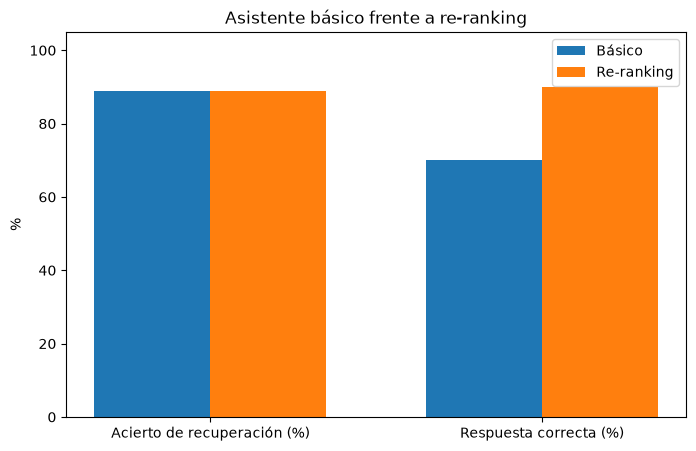

In [17]:
x = np.arange(len(resumen.index))
ancho = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - ancho / 2, resumen['Básico'], ancho, label='Básico')
ax.bar(x + ancho / 2, resumen['Re-ranking'], ancho, label='Re-ranking')
ax.set_xticks(x)
ax.set_xticklabels(resumen.index)
ax.set_ylim(0, 105)
ax.set_ylabel('%')
ax.set_title('Asistente básico frente a re-ranking')
ax.legend()
plt.savefig('../outputs/comparativa_reranking.png', bbox_inches='tight')
plt.show()

# Revisión manual de las respuestas

Como el juez es automático, mostramos las respuestas de las dos versiones para revisarlas a mano.

In [18]:
for i in range(len(resultados)):
    print(i + 1, resultados['pregunta'][i])
    print('BÁSICO:', resultados['texto_basico'][i][:400])
    print('RE-RANKING:', resultados['texto_reranking'][i][:400])
    print('-' * 60)

1 ¿Abre el taller los sábados?
BÁSICO: Sí, el taller abre los sábados de 9:00 a 13:00 (solo para entregas y recogidas).  
Fuente: faq_taller.md.
RE-RANKING: Sí, el taller abre los sábados de 9:00 a 13:00 (solo para entregas y recogidas).  
Fuente: faq_taller.md.
------------------------------------------------------------
2 ¿Cuándo es gratis el coche de sustitución?
BÁSICO: El coche de sustitución es gratuito cuando la reparación supera los 300 € (y la reparación dura más de un día, con disponibilidad).  
Fuente: **faq_taller.md**.
RE-RANKING: El coche de sustitución es gratuito cuando la reparación supera los 300 € (además de que la reparación deba durar más de un día y haya disponibilidad). 【faq_taller.md】
------------------------------------------------------------
3 ¿Cuánto dura la garantía de una reparación en un taller?
BÁSICO: La garantía de una reparación es de **tres meses o 2 000 km**, lo que ocurra antes. En el caso de vehículos industriales, la garantía es de **quince días 

# Conclusiones

- **Recuperación:** las dos versiones aciertan 8 de 9 preguntas (88,9 %). En este conjunto el re-ranking no mejora la métrica de recuperación, porque el bi-encoder ya traía un trozo con la fuente correcta casi siempre.
- **Respuestas:** el re-ranking pasa de 8 a 9 respuestas correctas (80 % a 90 %). La diferencia es la pregunta de Valladolid: con re-ranking entra en los 4 trozos el que contiene la estación 4705 de Peñafiel y la respuesta sale completa; con la búsqueda básica falta esa estación.
- **Matiz importante:** en el ejemplo lado a lado la versión con re-ranking también incluye Peñafiel, pero en una ejecución anterior del mismo ejemplo se la dejó. El LLM no responde exactamente igual cada vez, aunque la temperatura sea baja, así que con 10 preguntas una sola diferencia no es una prueba sólida: la mejora es pequeña y hay que tomarla con prudencia.
- **Utrera falla en las dos versiones:** el trozo con la estación 4131 de Utrera no entra ni entre los 20 candidatos del bi-encoder, así que el re-ranking no puede rescatarlo. El re-ranking solo reordena lo que ya ha encontrado la primera búsqueda. Una mejora para el futuro sería trocear el CSV por estación (una fila por trozo) en lugar de por 800 caracteres.
- **La métrica de recuperación de Valladolid es generosa:** cuenta como acierto que aparezca cualquier estación de Valladolid, aunque falte alguna.
- **Fuera de tema:** las dos versiones responden No lo sé, como se pide.
- **Coste:** el re-ranking añade un modelo de unos 470 MB y algo más de tiempo por pregunta (puntúa 20 parejas), asumible en un portátil.
- **Juez automático:** al revisar las respuestas a mano coincidimos con las calificaciones del juez en las 20 respuestas.